# 实验8：图像滤波

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

比较均值、高斯、中值滤波，理解噪声抑制与细节保留的取舍，并尝试高频增强。

## 实验原理

平滑滤波常降低噪声，也会削弱细节；中值是非线性滤波，通常适合椒盐噪声。滤波既可用于灰度图也可用于彩色图，本实验为便于比较统一使用灰度。本实验给瓶盖图添加可控噪声，固定随机种子，原图不被覆盖。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab08"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 为瓶盖生成两类噪声

高斯噪声 sigma=20；椒盐噪声总比例为 5%。噪声图保存到 `assets/generated/`，用于比较三种滤波器的处理效果。


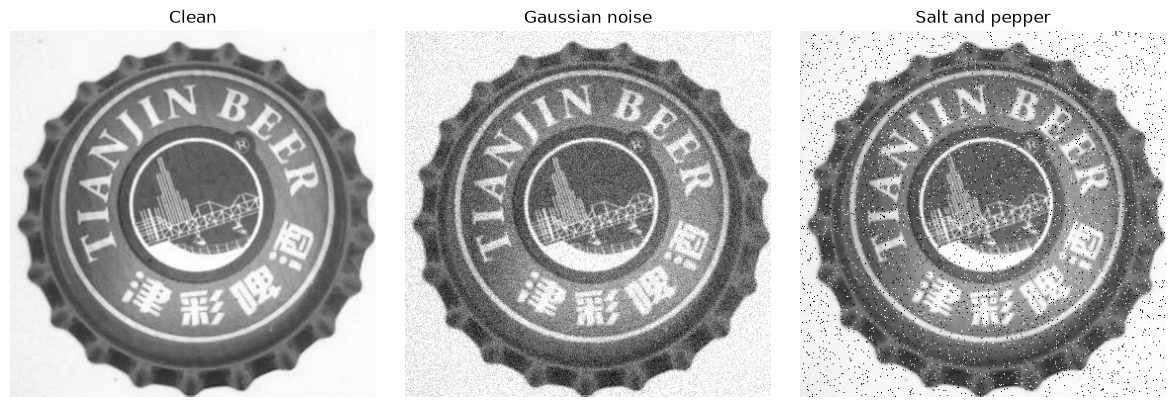

In [2]:
clean = read_image(ASSETS / "pdf/bottle_cap.png", gray=True)
rng = np.random.default_rng(2026)
gaussian = np.clip(clean.astype(np.float32) + rng.normal(0, 20, clean.shape), 0, 255).astype(np.uint8)
salt_pepper = clean.copy()
u = rng.random(clean.shape)
salt_pepper[u < 0.025] = 0
salt_pepper[u > 0.975] = 255
save_image(ASSETS / "generated/cap_gaussian_noise.png", gaussian)
save_image(ASSETS / "generated/cap_salt_pepper.png", salt_pepper)
show_images({"Clean": clean, "Gaussian noise": gaussian, "Salt and pepper": salt_pepper}, cols=3,
            save_to=OUT / "noise_inputs.png")


## 3. 比较三种滤波器

核大小均设为 5。MSE 是相对干净图的平均平方误差，越小越好；它不能代替对边缘和细节的观察，也不能据此断言某种滤波器始终最佳。


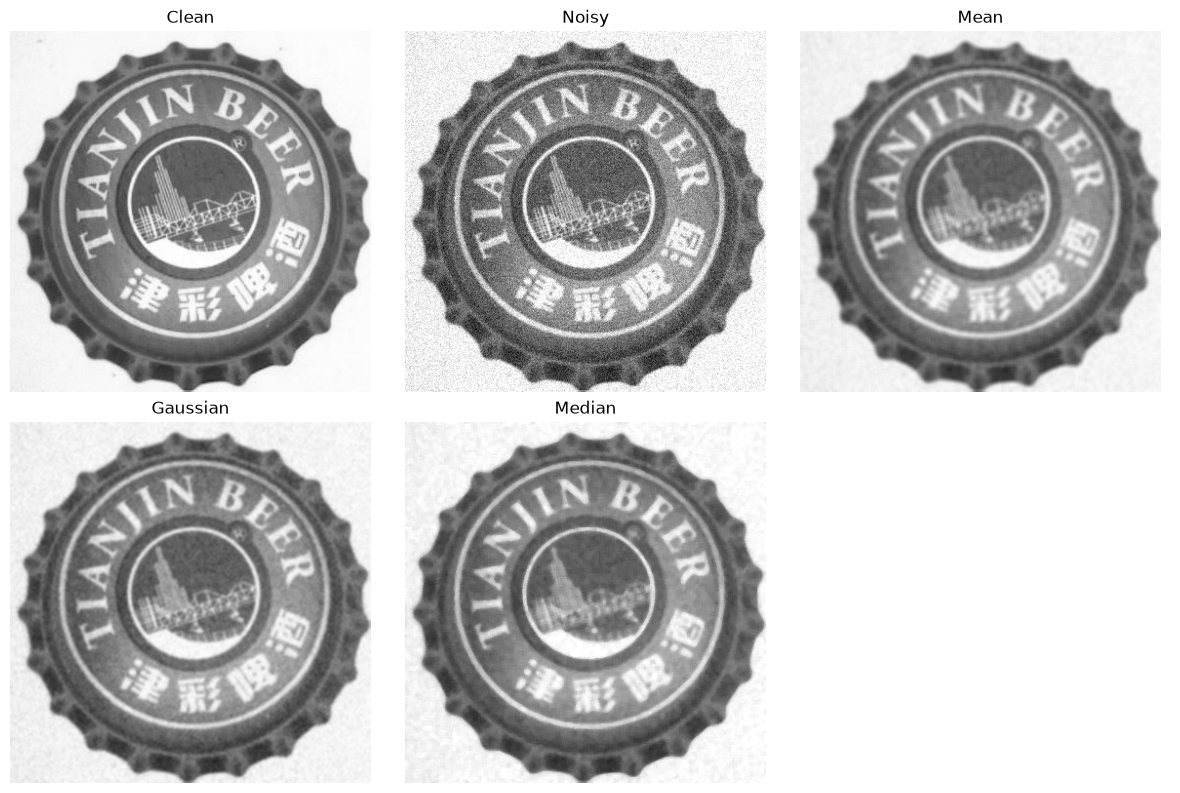

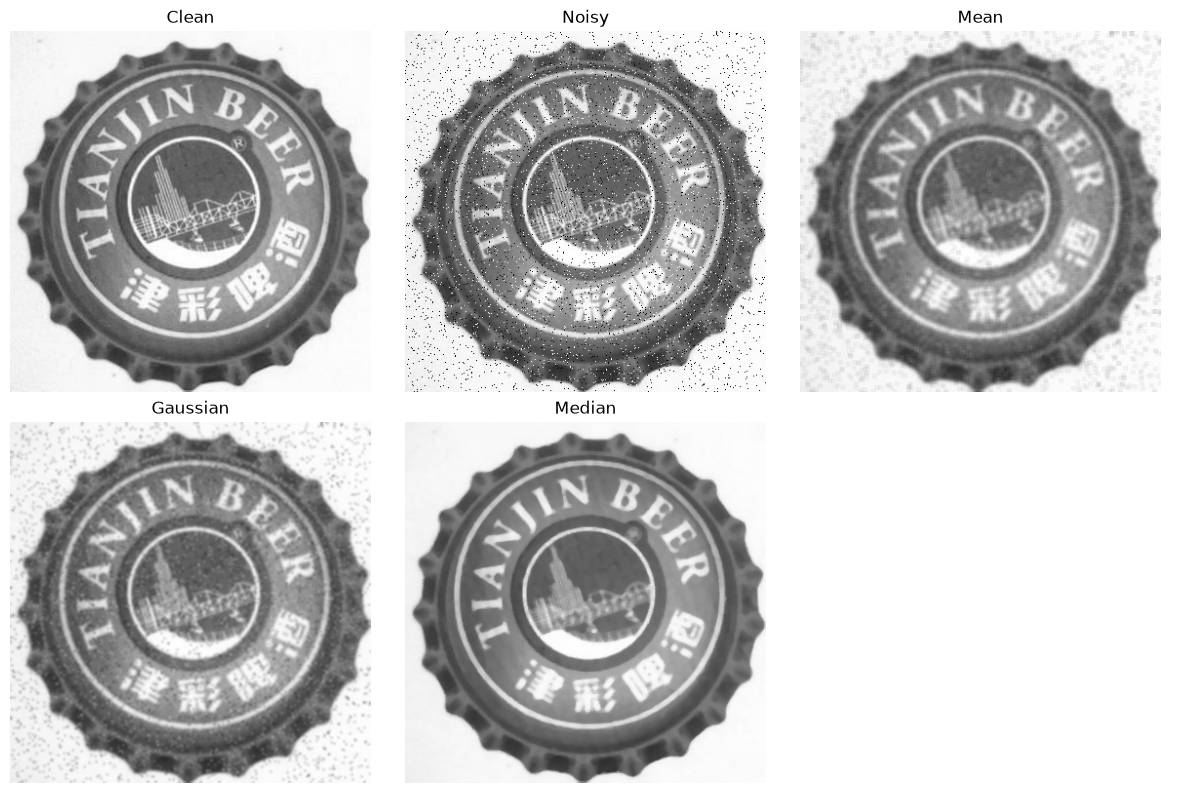

gaussian     Noisy    MSE=343.57
gaussian     Mean     MSE=122.97
gaussian     Gaussian MSE=78.62
gaussian     Median   MSE=91.55
salt_pepper  Noisy    MSE=1098.16
salt_pepper  Mean     MSE=167.45
salt_pepper  Gaussian MSE=138.45
salt_pepper  Median   MSE=51.20


In [3]:
import csv
filters = {
    "Mean": lambda a: cv2.blur(a, (5, 5)),
    "Gaussian": lambda a: cv2.GaussianBlur(a, (5, 5), 1.2),
    "Median": lambda a: cv2.medianBlur(a, 5),
}
def mse(a, b):
    return float(np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2))

rows = []
for noise_name, noisy in [("gaussian", gaussian), ("salt_pepper", salt_pepper)]:
    results = {"Clean": clean, "Noisy": noisy}
    rows.append([noise_name, "Noisy", mse(clean, noisy)])
    for filter_name, apply in filters.items():
        filtered = apply(noisy)
        results[filter_name] = filtered
        rows.append([noise_name, filter_name, mse(clean, filtered)])
        save_image(OUT / f"{noise_name}_{filter_name.lower()}.png", filtered)
    show_images(results, cols=3, save_to=OUT / f"{noise_name}_comparison.png")
with (OUT / "mse.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f); writer.writerow(["noise", "filter", "mse"]); writer.writerows(rows)
for noise_name, filter_name, error in rows:
    print(f"{noise_name:12} {filter_name:8} MSE={error:.2f}")


## 4. 电路板滤波与高频增强

先对电路板灰度图进行高斯和中值滤波，比较元件边界与细节的变化。高频分量为原图减去低通图，使用浮点数保留负值；增强图为原图加上一定比例的高频分量。


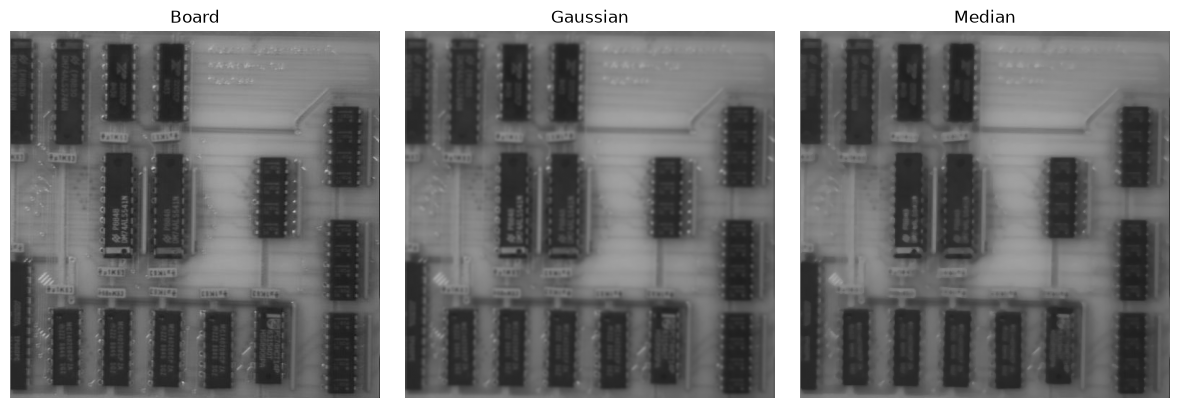

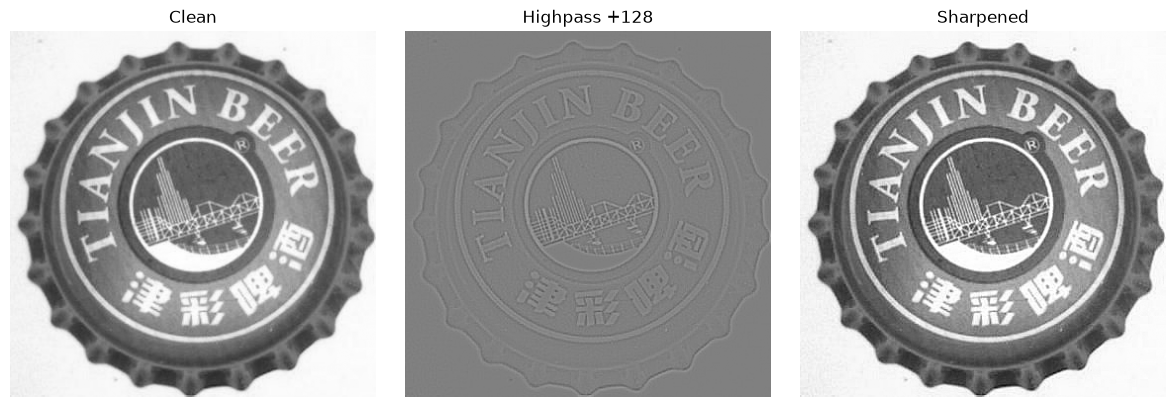

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab08/cap_sharpened.png')

In [4]:
board = read_image(ASSETS / "pdf/circuit_board.png", gray=True)
show_images({"Board": board, "Gaussian": cv2.GaussianBlur(board, (5, 5), 1.5),
             "Median": cv2.medianBlur(board, 5)}, cols=3,
            save_to=OUT / "board_filters.png")
lowpass = cv2.GaussianBlur(clean, (5, 5), 1.2).astype(np.float32)
highpass = clean.astype(np.float32) - lowpass
amount = 1.0
sharpened = np.clip(clean.astype(np.float32) + amount * highpass, 0, 255).astype(np.uint8)
# 高频图加 128 仅为便于显示，不参与增强计算。
highpass_display = np.clip(highpass + 128, 0, 255).astype(np.uint8)
show_images({"Clean": clean, "Highpass +128": highpass_display, "Sharpened": sharpened}, cols=3,
            save_to=OUT / "highpass_sharpening.png")
save_image(OUT / "cap_sharpened.png", sharpened)


## 作业：导出对比图

选择一种滤波方法即可。默认使用中值滤波处理椒盐噪声；本次作业只观察噪点变化，不要求计算误差或解释公式。

提交要求见 [一次实验作业](../assignments/README.md)。

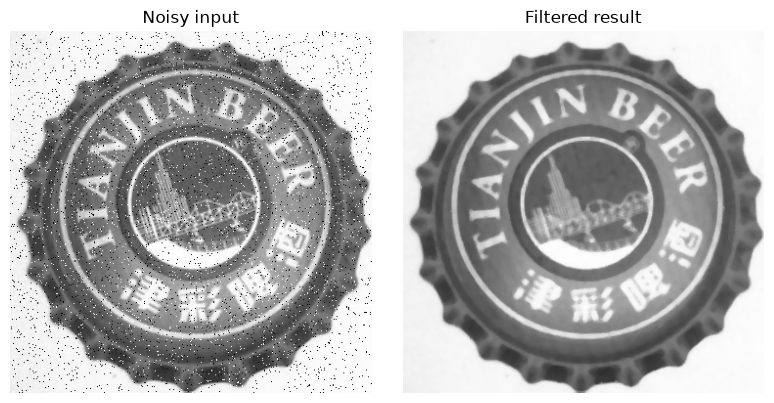

作业图片已保存到： /Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab08/03_filter.png


In [5]:
# 默认使用中值滤波。也可以将这一行替换为下方任意一行。
filtered_for_submission = cv2.medianBlur(salt_pepper, 5)
# filtered_for_submission = cv2.blur(salt_pepper, (5, 5))
# filtered_for_submission = cv2.GaussianBlur(salt_pepper, (5, 5), 1.2)
show_images({"Noisy input": salt_pepper, "Filtered result": filtered_for_submission}, cols=2,
            save_to=OUT / "03_filter.png")
print("作业图片已保存到：", OUT / "03_filter.png")

## 记录与思考

1. 对椒盐噪声，哪种滤波器效果更好？结合 MSE 和图像说明。
2. 将核从 5×5 改为 3×3、9×9，观察文字与瓶盖齿边。
3. 为什么锐化可能放大噪声？
4. 可选：将 clean 换成熊猫灰度图，重新生成噪声，保持随机种子不变。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab08/`；运行本 Notebook 不会改写原始素材。
